# Wellness Tourism Package Purchase Prediction

This project predicts whether a customer is likely to purchase the Wellness Tourism Package using historical customer data from Visit with Us.

The dataset contains a binary target variable, `ProdTaken` (1 = purchased, 0 = not purchased). Because the dataset does not separately identify Wellness Tourism Package purchases, this project assumes that `ProdTaken` represents Wellness Tourism Package purchase status.

The course team has confirmed that this interpretation is acceptable when clearly documented and consistently applied.

This assumption is a limitation because the dataset does not independently verify the package type.

Decision Tree, Random Forest, and Gradient Boosting models are compared using cross-validation. The selected model is evaluated on a held-out test set and used in a Streamlit prediction application.

**Repository:** [Tourism-Package-Predictions](https://github.com/Maverick-Manoj/Tourism-Package-Predictions)

In [1]:
from pathlib import Path
import os
import subprocess
import sys

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from sklearn.metrics import ConfusionMatrixDisplay, precision_recall_curve

# Find the project folder when running from the repository or notebooks folder.
locations = [Path.cwd(), Path.cwd().parent]
ROOT = next(
    (folder for folder in locations if (folder / "data" / "tourism.csv").exists()),
    None,
)
if ROOT is None:
    raise FileNotFoundError(
        "Cannot find data/tourism.csv. Open this notebook from the cloned "
        "tourism-package-prediction repository."
    )

os.chdir(ROOT)
print(f"Project: {ROOT.name}")
print(f"Python: {sys.version.split()[0]}")
print(f"Pandas: {pd.__version__}")

Project: tourism-package-prediction
Python: 3.13.5
Pandas: 2.2.3


## 1. Inspect and validate the dataset

I begin by checking the expected columns, the binary purchase target, unique customer IDs, and missing values. The same checks are implemented in `src/validate_data.py` so that the GitHub workflow can run them without the notebook.

In [2]:
from src.validate_data import validate_file

validation = validate_file(ROOT / "data" / "tourism.csv")
raw = pd.read_csv(ROOT / "data" / "tourism.csv")

print(f"Rows: {len(raw):,}")
print(f"Columns: {len(raw.columns)}")
print(f"Missing values: {raw.isna().sum().sum():,}")
display(raw.head())
display(raw.isna().sum().rename("missing_values").to_frame())

Data validation summary
{
  "dataset": "data/tourism.csv",
  "rows": 4128,
  "columns": 21,
  "missing_cells": 0,
  "duplicate_customer_ids": 0,
  "target_distribution": {
    "0": 3331,
    "1": 797
  },
  "purchase_rate": 0.193072,
  "unrecognized_columns": [],
  "validation_status": "PASS"
}
Rows: 4,128
Columns: 21
Missing values: 0


,Unnamed: 0,CustomerID,ProdTaken,Age,TypeofContact,CityTier,DurationOfPitch,Occupation,Gender,NumberOfPersonVisiting,NumberOfFollowups,ProductPitched,PreferredPropertyStar,MaritalStatus,NumberOfTrips,Passport,PitchSatisfactionScore,OwnCar,NumberOfChildrenVisiting,Designation,MonthlyIncome
0,0,200000,1,41.0,Self Enquiry,3,6.0,Salaried,Female,3,3.0,Deluxe,3.0,Single,1.0,1,2,1,0.0,Manager,20993.0
1,1,200001,0,49.0,Company Invited,1,14.0,Salaried,Male,3,4.0,Deluxe,4.0,Divorced,2.0,0,3,1,2.0,Manager,20130.0
2,2,200002,1,37.0,Self Enquiry,1,8.0,Free Lancer,Male,3,4.0,Basic,3.0,Single,7.0,1,3,0,0.0,Executive,17090.0
3,3,200003,0,33.0,Company Invited,1,9.0,Salaried,Female,2,3.0,Basic,3.0,Divorced,2.0,1,5,1,1.0,Executive,17909.0
4,5,200005,0,32.0,Company Invited,1,8.0,Salaried,Male,3,3.0,Basic,3.0,Single,1.0,0,5,1,1.0,Executive,18068.0


,missing_values
Unnamed: 0,0
CustomerID,0
ProdTaken,0
Age,0
TypeofContact,0
CityTier,0
DurationOfPitch,0
Occupation,0
Gender,0
NumberOfPersonVisiting,0


## 2. Examine purchase outcomes and categorical values

Most customers have `ProdTaken = 0`, indicating no purchase under the project's Wellness Tourism Package assumption. Because purchases are less frequent than non-purchases, accuracy alone may be misleading. Model comparison therefore emphasizes average precision and also reports ROC-AUC.

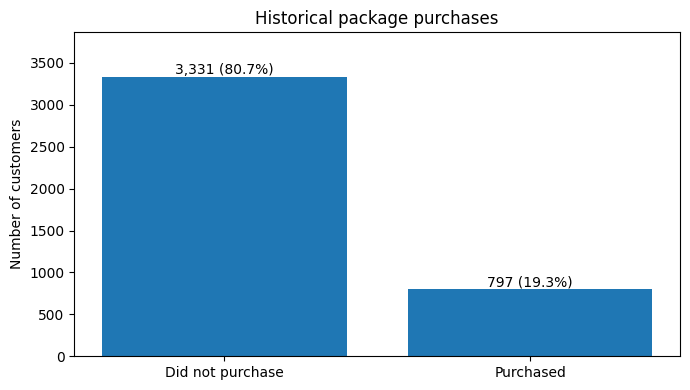

Gender values: ['Fe Male', 'Female', 'Male']
Marital status values: ['Divorced', 'Married', 'Single', 'Unmarried']
Duplicate rows: 0
Majority-class accuracy: 80.7%


In [3]:
purchase_counts = raw["ProdTaken"].value_counts().reindex([0, 1])
fig, ax = plt.subplots(figsize=(7, 4))
labels = ["Did not purchase", "Purchased"]
bars = ax.bar(labels, purchase_counts.values)

for bar, count in zip(bars, purchase_counts.values):
    ax.annotate(
        f"{count:,} ({count / len(raw):.1%})",
        (bar.get_x() + bar.get_width() / 2, bar.get_height()),
        ha="center",
        va="bottom",
    )

ax.set_ylim(0, purchase_counts.max() * 1.16)
ax.set_ylabel("Number of customers")
ax.set_title("Historical package purchases")
plt.tight_layout()
plt.show()

print("Gender values:", sorted(raw["Gender"].dropna().unique()))
print("Marital status values:", sorted(raw["MaritalStatus"].dropna().unique()))
print("Duplicate rows:", int(raw.duplicated().sum()))
print("Majority-class accuracy:", f"{purchase_counts[0] / len(raw):.1%}")

### Variables available at prediction time

The model uses customer information that could be available before a sales call.

I removed customer IDs, the extra index column, and fields related to the sales interaction. These would not be available when making a prediction before contacting the customer.

The cleaning function also changes `Fe Male` to `Female` and `Unmarried` to `Single`. Before using the model in a real campaign, I would confirm that the remaining fields are available.

In [4]:
from src.common import DROP_COLUMNS, FEATURE_COLUMNS, clean_data

cleaned = clean_data(raw)
print("Model features:", len(FEATURE_COLUMNS))
print("Excluded columns:", ", ".join(DROP_COLUMNS))
print("Prepared data shape:", cleaned.shape)
display(cleaned.head())

Model features: 13
Excluded columns: Unnamed: 0, CustomerID, TypeofContact, DurationOfPitch, NumberOfFollowups, ProductPitched, PitchSatisfactionScore
Prepared data shape: (4128, 14)


,Age,CityTier,Occupation,Gender,NumberOfPersonVisiting,PreferredPropertyStar,MaritalStatus,NumberOfTrips,Passport,OwnCar,NumberOfChildrenVisiting,Designation,MonthlyIncome,ProdTaken
0,41.0,3,Salaried,Female,3,3.0,Single,1.0,1,1,0.0,Manager,20993.0,1
1,49.0,1,Salaried,Male,3,4.0,Divorced,2.0,0,1,2.0,Manager,20130.0,0
2,37.0,1,Free Lancer,Male,3,3.0,Single,7.0,1,0,0.0,Executive,17090.0,1
3,33.0,1,Salaried,Female,2,3.0,Divorced,2.0,1,1,1.0,Executive,17909.0,0
4,32.0,1,Salaried,Male,3,3.0,Single,1.0,0,1,1.0,Executive,18068.0,0


## 3. Prepare the training and test sets

An 80/20 stratified split preserves roughly the same purchase rate in each subset. The preparation script writes `train.csv` and `test.csv` to `build/`. In GitHub Actions, these files are passed from the preparation job to the training job as an artifact.

In [5]:
from src.prepare_data import prepare

train, test, split_summary = prepare(
    ROOT / "data" / "tourism.csv",
    ROOT / "build",
    test_size=0.20,
    seed=42,
)

sample_summary = []

for name, dataset in [("Training", train), ("Test", test)]:
    sample_summary.append({
        "sample": name,
        "customers": len(dataset),
        "purchases": int(dataset["ProdTaken"].sum()),
        "purchase_rate": dataset["ProdTaken"].mean()
    })

display(pd.DataFrame(sample_summary))

Data validation summary
{
  "dataset": "data/tourism.csv",
  "rows": 4128,
  "columns": 21,
  "missing_cells": 0,
  "duplicate_customer_ids": 0,
  "target_distribution": {
    "0": 3331,
    "1": 797
  },
  "purchase_rate": 0.193072,
  "unrecognized_columns": [],
  "validation_status": "PASS"
}


Data preparation summary
{
  "train_rows": 3302,
  "test_rows": 826,
  "train_positive_rate": 0.193216,
  "test_positive_rate": 0.192494,
  "feature_columns": [
    "Age",
    "CityTier",
    "Occupation",
    "Gender",
    "NumberOfPersonVisiting",
    "PreferredPropertyStar",
    "MaritalStatus",
    "NumberOfTrips",
    "Passport",
    "OwnCar",
    "NumberOfChildrenVisiting",
    "Designation",
    "MonthlyIncome"
  ],
  "train_file": "build/train.csv",
  "test_file": "build/test.csv",
  "test_size": 0.2,
  "random_state": 42
}


,sample,customers,purchases,purchase_rate
0,Training,3302,638,0.193216
1,Test,826,159,0.192494


## 4. Compare classification models

I compared three models: Decision Tree, Random Forest, and Gradient Boosting.

Each model was tuned using 3-fold stratified cross-validation. Missing values and categorical variables were handled within the training pipeline. I selected the model with the highest average precision score.

The training script records parameter combinations in `reports/experiments.json` and also logs to MLflow when installed. The test set is reserved for evaluating the chosen model.

In [6]:
from src.train_model import experiment

best_model, metrics, trials = experiment(
    ROOT / "build" / "train.csv",
    ROOT / "build" / "test.csv",
    ROOT / "models",
    ROOT / "reports",
    ROOT / "mlruns",
)

print("Selected model:", metrics["selected_algorithm"])
print("Cross-validated average precision:", f"{metrics['selected_cv_pr_auc']:.3f}")
print("Experiment records:", len(trials))

DecisionTree: mean CV average precision = 0.5530


RandomForest: mean CV average precision = 0.7001


GradientBoosting: mean CV average precision = 0.6059
Selected model: RandomForest
Test ROC-AUC: 0.915
Test average precision: 0.718
              precision    recall  f1-score   support

           0       0.88      0.98      0.93       667
           1       0.85      0.42      0.56       159

    accuracy                           0.87       826
   macro avg       0.86      0.70      0.74       826
weighted avg       0.87      0.87      0.85       826

Selected model: RandomForest
Cross-validated average precision: 0.700
Experiment records: 12


,algorithm,best_cv_pr_auc,best_params
0,DecisionTree,0.553047,"{'classifier__max_depth': 8, 'classifier__min_..."
1,RandomForest,0.700142,"{'classifier__max_depth': None, 'classifier__m..."
2,GradientBoosting,0.605899,"{'classifier__learning_rate': 0.1, 'classifier..."


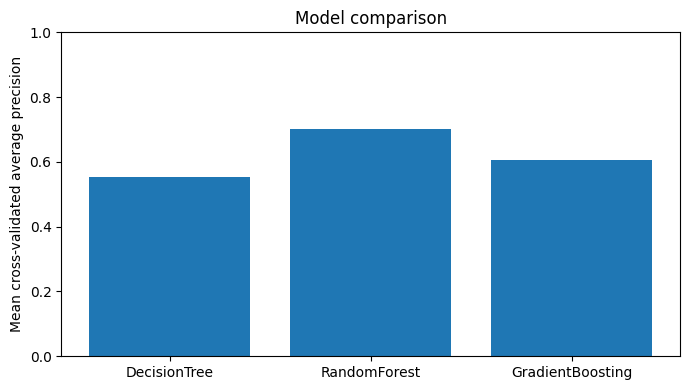

,algorithm,trial,parameters,cv_mean_pr_auc,cv_std_pr_auc,cv_mean_roc_auc
7,RandomForest,4,"{'classifier__max_depth': None, 'classifier__m...",0.700142,0.014577,0.893623
6,RandomForest,3,"{'classifier__max_depth': None, 'classifier__m...",0.698146,0.012074,0.892626
5,RandomForest,2,"{'classifier__max_depth': 6, 'classifier__min_...",0.613643,0.019764,0.836940
4,RandomForest,1,"{'classifier__max_depth': 6, 'classifier__min_...",0.610944,0.022018,0.837940
11,GradientBoosting,4,"{'classifier__learning_rate': 0.1, 'classifier...",0.605899,0.014924,0.825535
10,GradientBoosting,3,"{'classifier__learning_rate': 0.1, 'classifier...",0.598927,0.015988,0.820411
9,GradientBoosting,2,"{'classifier__learning_rate': 0.05, 'classifie...",0.592133,0.016431,0.815973
8,GradientBoosting,1,"{'classifier__learning_rate': 0.05, 'classifie...",0.583585,0.018208,0.809707
3,DecisionTree,4,"{'classifier__max_depth': 8, 'classifier__min_...",0.553047,0.014196,0.796054
2,DecisionTree,3,"{'classifier__max_depth': 8, 'classifier__min_...",0.548784,0.034038,0.788283


In [7]:
model_comparison = pd.DataFrame(metrics["cv_results_by_model"])
display(model_comparison)

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(model_comparison["algorithm"], model_comparison["best_cv_pr_auc"])
ax.set_ylim(0, 1)
ax.set_ylabel("Mean cross-validated average precision")
ax.set_title("Model comparison")
plt.tight_layout()
plt.show()

display(
    pd.DataFrame(trials)
    .sort_values("cv_mean_pr_auc", ascending=False)
    .head(10)
)

## 5. Evaluate on the test set

I evaluated the selected model using the 20% test set that was kept aside during training. I report average precision and ROC-AUC, along with precision, recall, and F1 using a 0.50 probability cutoff. This cutoff is only a starting point and has not been adjusted for campaign costs.

In [8]:
from src.evaluate_model import evaluate

saved_model_metrics = evaluate(
    ROOT / "models" / "best_model.joblib",
    ROOT / "build" / "test.csv",
)

metric_labels = {
    "Cross-validation average precision": "selected_cv_pr_auc",
    "Test average precision": "holdout_average_precision",
    "Test ROC-AUC": "holdout_roc_auc",
    "Precision at 0.50": "holdout_precision_at_0_5",
    "Recall at 0.50": "holdout_recall_at_0_5",
    "F1 at 0.50": "holdout_f1_at_0_5",
    "Accuracy at 0.50": "holdout_accuracy_at_0_5",
}
display(pd.DataFrame([
    {"metric": label, "value": metrics[key]}
    for label, key in metric_labels.items()
]))

Saved model evaluation
{
  "holdout_pr_auc": 0.7184777742339935,
  "holdout_roc_auc": 0.9154007901709522,
  "num_records": 826,
  "num_scores": 826
}


,metric,value
0,Cross-validation average precision,0.700142
1,Test average precision,0.718478
2,Test ROC-AUC,0.915401
3,Precision at 0.50,0.846154
4,Recall at 0.50,0.415094
5,F1 at 0.50,0.556962
6,Accuracy at 0.50,0.872881


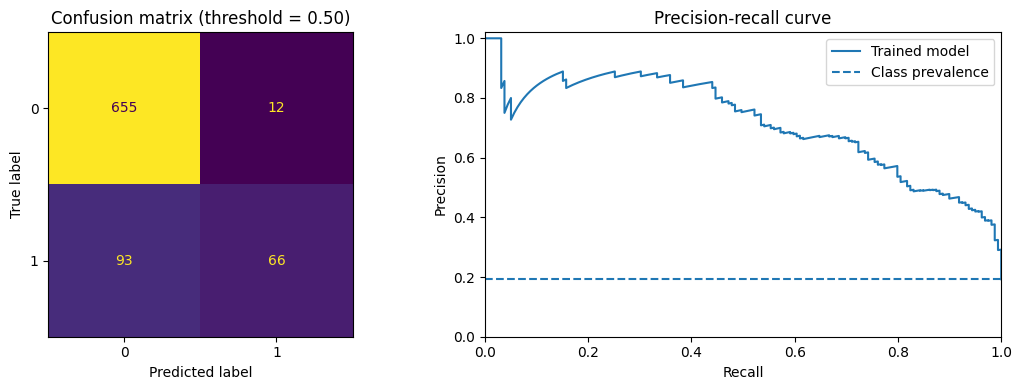

In [9]:
X_test = test[FEATURE_COLUMNS]
y_test = test["ProdTaken"].astype(int)
probabilities = best_model.predict_proba(X_test)[:, 1]

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
ConfusionMatrixDisplay.from_predictions(
    y_test,
    (probabilities >= 0.50).astype(int),
    ax=axes[0],
    colorbar=False,
)
axes[0].set_title("Confusion matrix (threshold = 0.50)")

precision, recall, _ = precision_recall_curve(y_test, probabilities)
axes[1].plot(recall, precision, label="Trained model")
axes[1].axhline(y_test.mean(), linestyle="--", label="Class prevalence")
axes[1].set(
    xlabel="Recall",
    ylabel="Precision",
    title="Precision-recall curve",
    xlim=(0, 1),
    ylim=(0, 1.02),
)
axes[1].legend()
plt.tight_layout()
plt.show()

## 6. Does the model help rank prospective customers?

Under the documented target assumption, higher model scores identify customers with a greater estimated likelihood of purchasing the Wellness Tourism Package. Ranking lift measures how effectively the model concentrates historical purchases among higher-scoring customers. It does not establish that marketing contact causes additional purchases.

The chart shows historical purchase rates for each score decile.

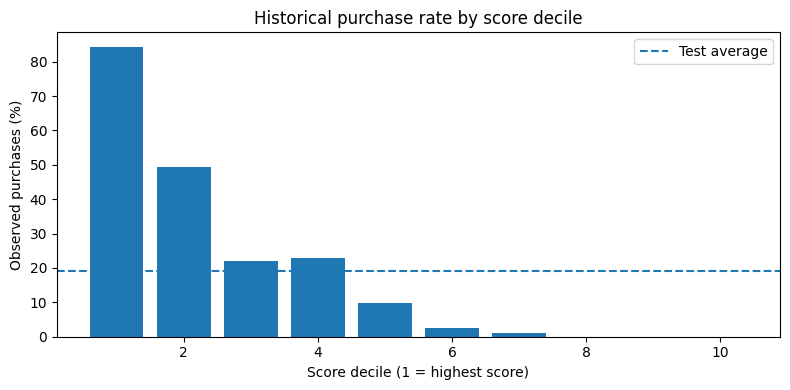

The top 20% of scores had a purchase rate of 66.9%, compared with 19.2% overall. Ranking lift: 3.47x.


In [10]:
ranking = pd.DataFrame({
    "purchase": y_test.to_numpy(),
    "score": probabilities,
}).sort_values("score", ascending=False).reset_index(drop=True)

ranking["decile"] = (
    np.minimum(10 * np.arange(len(ranking)) // len(ranking), 9) + 1
)
by_decile = ranking.groupby("decile", as_index=False).agg(
    purchase_rate=("purchase", "mean"),
    customers=("purchase", "size"),
)

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(by_decile["decile"], 100 * by_decile["purchase_rate"])
ax.axhline(100 * y_test.mean(), linestyle="--", label="Test average")
ax.set(
    xlabel="Score decile (1 = highest score)",
    ylabel="Observed purchases (%)",
    title="Historical purchase rate by score decile",
)
ax.legend()
plt.tight_layout()
plt.show()

print(
    f"The top 20% of scores had a purchase rate of "
    f"{metrics['top_20pct_positive_rate']:.1%}, compared with "
    f"{metrics['test_positive_rate']:.1%} overall. "
    f"Ranking lift: {metrics['top_20pct_lift']:.2f}x."
)

## 7. Review feature importance

I checked which features contributed most to the selected tree-based model. The chart shows impurity-based feature importance, which describes how the model makes splits, not whether a feature causes someone to buy a package.

,importance
numeric__Age,0.166413
numeric__MonthlyIncome,0.164735
numeric__Passport,0.124786
numeric__NumberOfTrips,0.077516
numeric__PreferredPropertyStar,0.054817
category__Designation_Executive,0.048867
numeric__CityTier,0.047713
category__MaritalStatus_Single,0.041082
numeric__NumberOfChildrenVisiting,0.036432
numeric__NumberOfPersonVisiting,0.032401


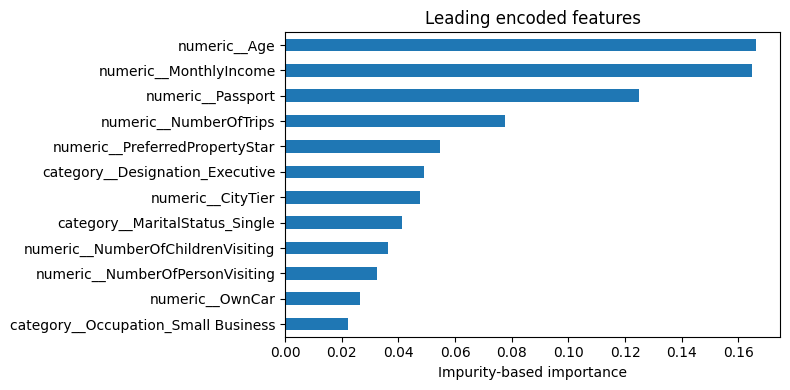

In [11]:
preprocessor = best_model.named_steps["preprocessor"]
classifier = best_model.named_steps["classifier"]
feature_names = preprocessor.get_feature_names_out()

feature_importance = pd.Series(
    classifier.feature_importances_,
    index=feature_names
).sort_values(ascending=False)

print("Selected model:", metrics["selected_algorithm"])

display(feature_importance.head(12).to_frame("importance"))
fig, ax = plt.subplots(figsize=(8, 4))
feature_importance.head(12).sort_values().plot.barh(ax=ax)
ax.set_xlabel("Feature importance")
ax.set_title("Most important features")
plt.tight_layout()
plt.show()

## 8. Streamlit model interface

The Streamlit app in `app.py` builds a one-row DataFrame from the customer form and calls `predict_proba` on the saved preprocessing and classification pipeline. The model and metadata are loaded from `models/`.

The interface can be deployed from this repository using Streamlit Community Cloud. A Dockerfile is also available for a Hugging Face Space if the additional deployment is required.

In [12]:
required_files = {
    "Customer dataset": ROOT / "data" / "tourism.csv",
    "Streamlit app": ROOT / "app.py",
    "App dependencies": ROOT / "requirements.txt",
    "Trained model": ROOT / "models" / "best_model.joblib",
    "Model metadata": ROOT / "models" / "model_metadata.json",
    "Experiment results": ROOT / "reports" / "experiments.json",
    "GitHub Actions workflow": ROOT / ".github" / "workflows" / "pipeline.yml",
}

for label, path in required_files.items():
    print(f"{label}: {'Found' if path.is_file() else 'Missing'}")

assert all(path.is_file() for path in required_files.values())

Customer dataset: Found
Streamlit app: Found
App dependencies: Found
Trained model: Found
Model metadata: Found
Experiment results: Found
GitHub Actions workflow: Found


## 9. Automated GitHub Actions pipeline

The GitHub Actions workflow runs four jobs in order: validate, prepare, train, and publish. Train and test files are passed between jobs as artifacts. The final job commits updated model and report files when needed.

The next cell checks the workflow definition. I verify completed runs separately on the GitHub Actions page.

In [13]:
import yaml

workflow_path = ROOT / ".github" / "workflows" / "pipeline.yml"
workflow = yaml.safe_load(workflow_path.read_text(encoding="utf-8"))

jobs = pd.DataFrame([
    {
        "job": name,
        "depends_on": job.get("needs", "None"),
        "steps": len(job["steps"]),
    }
    for name, job in workflow["jobs"].items()
])
display(jobs)
assert set(workflow["jobs"]) == {"validate", "prepare", "train", "publish"}

,job,depends_on,steps
0,validate,None,6
1,prepare,validate,5
2,train,prepare,8
3,publish,train,3


## 10. Test the project files

A small test suite checks the input schema, data cleaning, and serialized model predictions. The final evaluation script independently loads the saved model and scores the test set.

In [14]:
tests = subprocess.run(
    [sys.executable, "-m", "pytest", "-q"],
    cwd=ROOT,
    capture_output=True,
    text=True,
)
print(tests.stdout)
if tests.returncode:
    print(tests.stderr)
assert tests.returncode == 0

print("Scored test observations:", saved_model_metrics["num_scores"])

......                                                                   [100%]
6 passed in 0.89s

Scored test observations: 826


## 11. Findings and Business Recommendations

Three classification algorithms were compared using stratified cross-validation, and the best-performing model was selected using average precision. Its generalization performance was evaluated on the held-out test dataset.

Under the documented assumption that `ProdTaken` identifies Wellness Tourism Package purchases, the model can support customer prioritization for targeted marketing campaigns.

**Business recommendations:**

1. Prioritize higher-scoring customers for an initial, controlled marketing pilot.
2. Select an outreach threshold based on campaign capacity, contact costs, and the balance between precision and recall.
3. Monitor conversion rates and model performance using newer customer data.
4. Confirm the package-specific meaning of historical purchase records before using the results to make operational claims about Wellness package demand.

Model predictions describe associations in historical customer data. They do not prove that a particular marketing intervention will increase sales.

In [15]:
winner = max(
    metrics["cv_results_by_model"],
    key=lambda model: model["best_cv_pr_auc"],
)
print(f"Customers analyzed: {len(raw):,}")
print(f"Historical purchase rate: {raw['ProdTaken'].mean():.1%}")
print(f"Best model: {winner['algorithm']}")
print(f"Best cross-validation average precision: {winner['best_cv_pr_auc']:.3f}")
print(f"Test ROC-AUC: {metrics['holdout_roc_auc']:.3f}")
print(f"Test average precision: {metrics['holdout_average_precision']:.3f}")
print(f"Top 20% ranking lift: {metrics['top_20pct_lift']:.2f}x")

Customers analyzed: 4,128
Historical purchase rate: 19.3%
Best model: RandomForest
Best cross-validation average precision: 0.700
Test ROC-AUC: 0.915
Test average precision: 0.718
Top 20% ranking lift: 3.47x


## Project links and deployment evidence

- [GitHub repository](https://github.com/Maverick-Manoj/Tourism-Package-Predictions)
- [GitHub Actions runs](https://github.com/Maverick-Manoj/Tourism-Package-Predictions/actions)
- Streamlit app: https://tourism-package-predictions-lgjwmxlyarcygv33rfglg6.streamlit.app/
- Hugging Face Space: not linked here; add a URL after deployment